# Closed-system TCL validation

We begin by reproducing **Figure 8** of the manuscript: vacuum dispersion, the single-polariton-reference spectral function, and hard-window error propagation. All panels are recalculated from independently constructed sector Hamiltonians, not traced from the reference image.

The periodic 4x4 lattice has one emitter per cavity, cutoff 2, hopping 0.2, coupling 1, potential 1 and zero detuning. The vacuum, one- and two-excitation sectors have dimensions 1, 32 and 512. Both photon-addition and photon-removal correlators are included.

Additional exact-evolution, polynomial and circuit checks follow. This is small-system physical validation, not a large-lattice resource-instance statevector simulation.

In [1]:
from pathlib import Path
import os,sys,json,hashlib
os.environ.setdefault('MPLCONFIGDIR','/tmp/tcl-mpl')
os.environ.setdefault('NUMBA_CACHE_DIR','/tmp/tcl-numba')
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'resource_estimation/gqsp.py').is_file())
sys.path.insert(0,str(ROOT/'resource_estimation'))
sys.path.insert(0,str(ROOT/'validation'))
import numpy as np
import pandas as pd
from IPython.display import display,Image,Markdown
import gqsp as resources
import validation as validate


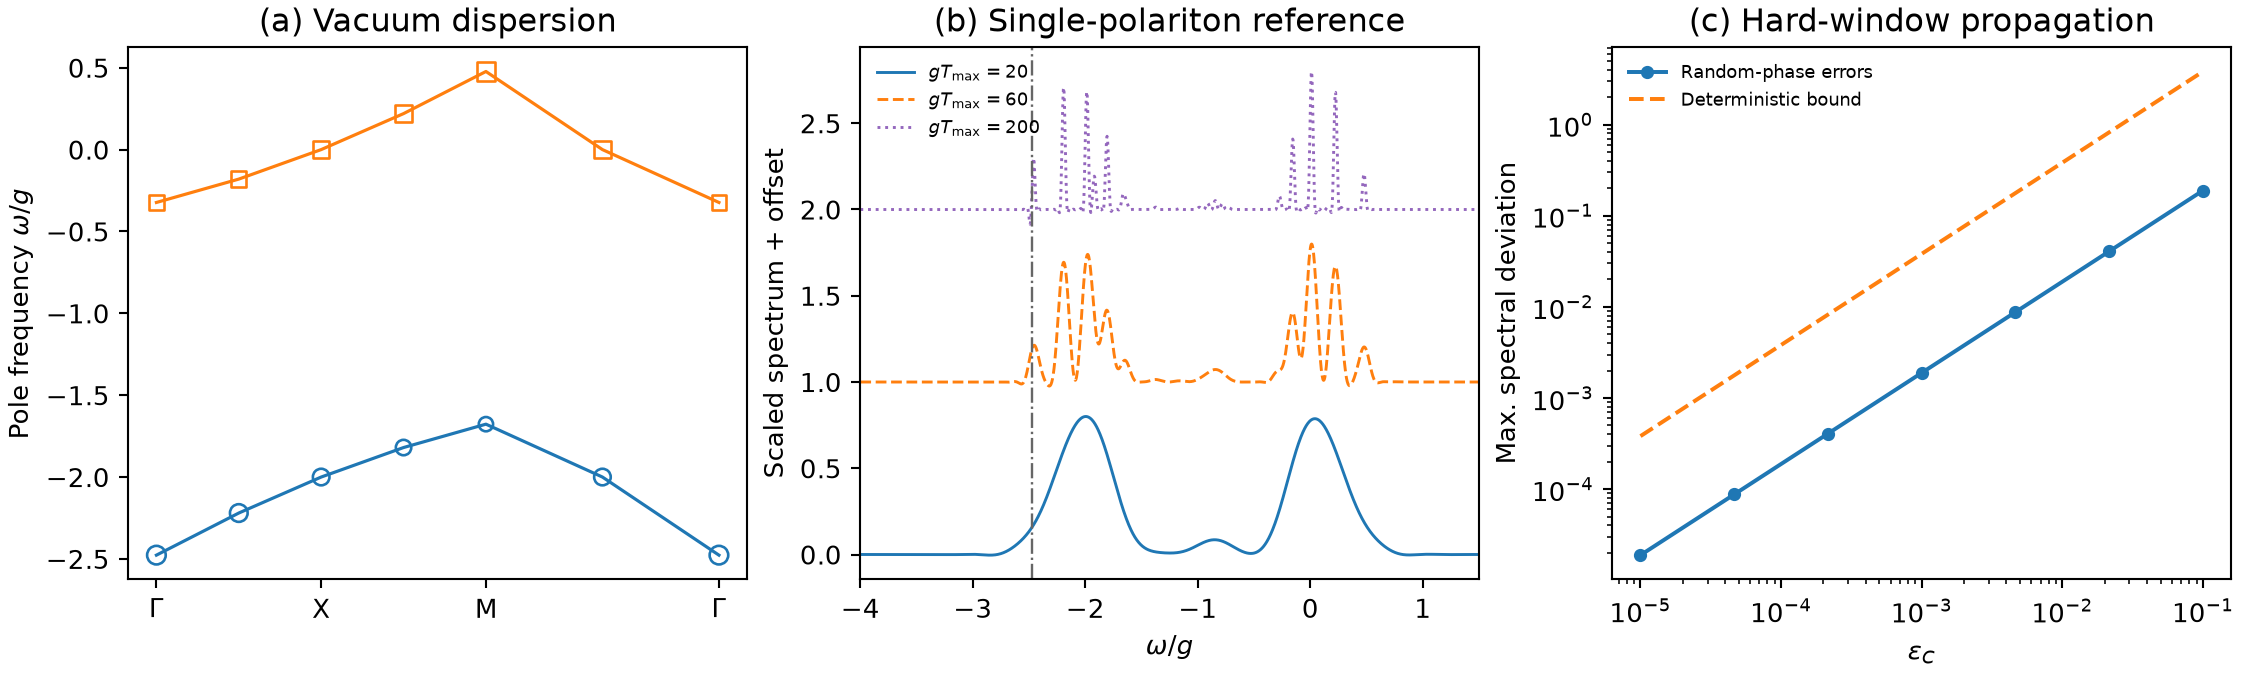

In [2]:
out=ROOT/'validation/results'
figure_path=out/'figure8_summary.json'
RECOMPUTE_FIGURE8=False
current=figure_path.exists() and json.loads(figure_path.read_text()).get('source_sha256')==hashlib.sha256(Path(validate.__file__).read_bytes()).hexdigest()
figure_report=validate.reproduce_figure8() if RECOMPUTE_FIGURE8 or not current else json.loads(figure_path.read_text())
assert figure_report['status']=='PASS'
display(Image(filename=str(out/'figure8_closed_system.png')))


**Figure 8 reproduction.** (a) Momentum-resolved photon-addition poles in the vacuum, compared with Eq. (123); marker area indicates photon weight. (b) The local retarded spectrum from Eqs. (17)--(20), using the lowest one-polariton eigenstate as the reference. Addition reaches the two-polariton sector and removal reaches the vacuum. The one-sided Hann window is used at $gT_{\max}=20,60,200$; curves are scaled to a common height and offset. The dash-dotted line marks the removal pole. (c) Independent complex errors of magnitude $\epsilon_C$ are added to both correlators, with random phases and seed 917. The hard-window trapezoidal grid has 601 points over $gT=60$; the deterministic bound is $2\epsilon_C T_{\max}/\pi$ (Eq. (119)).

The numerical grids and seed are recorded in `figure8_summary.json`; raw dispersion, spectrum and error data are exported as CSV files. The spectra use an analytic Hann transform of the exact Lehmann poles, independently checked against direct time quadrature. Panel (c) illustrates cancellation of random errors; it is not a measurement-shot concentration bound or a quantum-circuit validation.

In [3]:
fields=['reference_energy','addition_weight','removal_weight','removal_pole','nearest_addition_pole',
        'pole_frequency_error','photon_weight_error','commutator_sum_rule_error','hann_vs_time_quadrature_error']
display(pd.Series({key:figure_report[key] for key in fields},name='Figure 8 checks'))


reference_energy                -2.477033e+00
addition_weight                  1.042856e+00
removal_weight                   4.285596e-02
removal_pole                    -2.477033e+00
nearest_addition_pole           -2.464380e+00
pole_frequency_error             4.440892e-16
photon_weight_error              1.665335e-16
commutator_sum_rule_error        1.221245e-15
hann_vs_time_quadrature_error    1.867191e-14
Name: Figure 8 checks, dtype: float64

## Additional closed-system evolution and polynomial checks

status                                                                                         PASS
sector_dimensions                                                                      [1, 32, 512]
dispersion_eigenvalue_error                                                                     0.0
correlator_commutator_sum_rule_error                                                            0.0
matrix_exponential_vs_eigendecomposition_error                                                  0.0
max_excitation_conservation_error                                                               0.0
scope                                             Small classical sector and polynomial validati...
dtype: object

,degree,state_error
0,8,5.776257e-01
1,16,6.240949e-04
2,32,5.427196e-15
3,64,1.639304e-15


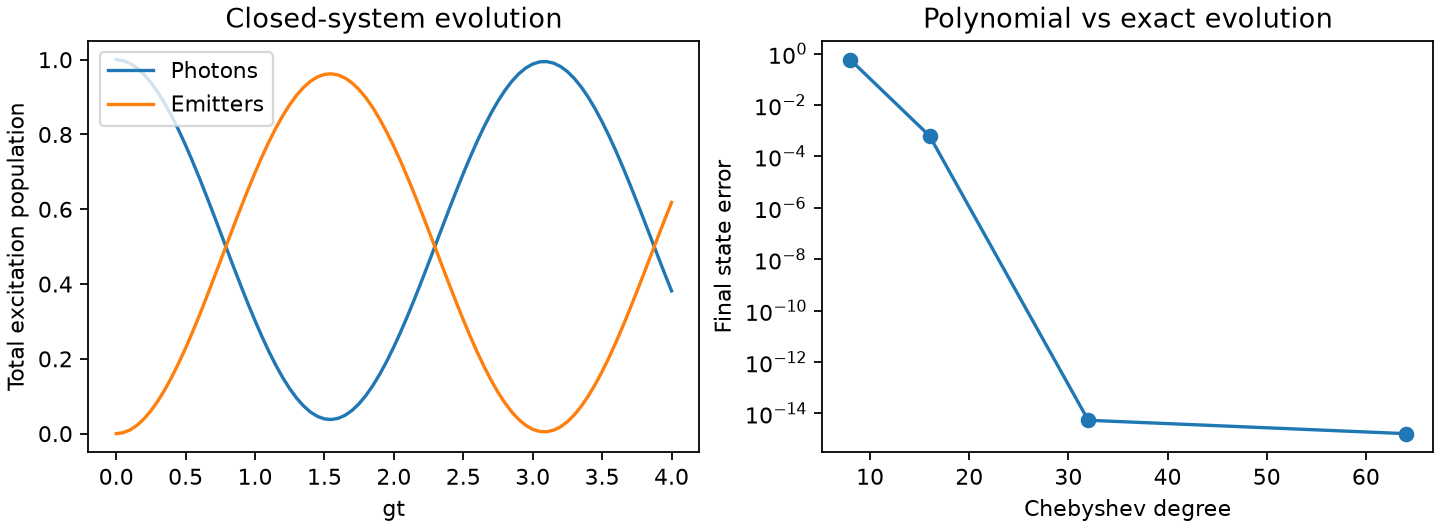

In [4]:
out=ROOT/'validation/results'
path=out/'closed_validation_summary.json'
RECOMPUTE=False
current=path.exists() and json.loads(path.read_text()).get('source_sha256')==hashlib.sha256(Path(validate.__file__).read_bytes()).hexdigest()
report=validate.run_closed() if RECOMPUTE or not current else json.loads(path.read_text())
assert report['status']=='PASS'
display(pd.Series({k:v for k,v in report.items() if k not in ('polynomial_convergence','source_sha256')}))
display(pd.DataFrame(report['polynomial_convergence']))
display(Image(filename=str(out/'closed_validation.png')))


## Numerical signal-processing check

Generate the first Table VI case's numerical GQSP factors and compare ideal/rounded signal responses against the target across walk eigenphases. This validates the signal layer, including absolute phases; Hamiltonian encoding and outer-selection errors are not included in this signal-only check. The generic resource schedule used for all manuscript cases does not itself supply a numerical phase list.

In [5]:
p=resources.closed_plan(*resources.CLOSED_CASES[0])
phases=resources.phase_build_phases(p)
certificate,response=resources.phase_validate_spectral(phases,grid_size=4097)
assert certificate['rounded_initialized_state_max']<float(p['epsilon'])
display(pd.Series(certificate))
response.to_csv(out/'closed_signal_response.csv',index=False)


grid_points                                                     4097
unrounded_polynomial_reconstruction_max                          0.0
reconstruction_coefficient_l1                                    0.0
unrounded_evolution_block_max                                    0.0
rounded_evolution_block_max                                 0.000003
unrounded_initialized_state_max                             0.000044
rounded_initialized_state_max                               0.000046
sampled_full_signal_operator_rounding_error                 0.000005
analytic_signal_rounding_bound                               0.00014
numerical_uniform_polynomial_error_bound                         0.0
numerical_uniform_initialized_signal_error_bound            0.000188
numerical_coefficient_bounds_are_interval_certified            False
complete_lattice_statevector_simulated                         False
Hamiltonian_encoding_error_included_in_signal_errors           False
outer_selection_rotation_error_inc

## Executed circuit checks

The consolidated test suite checks projected blocks, adjoints, inactive controls, both catalysts, and environment resets. The stored record is accepted only for the same validation and resource sources. Regenerate with `python validation/validation.py gates`.

In [6]:
gate_record=json.loads((out/'gate_validation.json').read_text())
assert gate_record['validation_sha256']==hashlib.sha256(Path(validate.__file__).read_bytes()).hexdigest()
assert gate_record['resources_sha256']==resources.source_hashes()
print(gate_record['pytest_output'])


........................                                                 [100%]
24 passed in 341.25s (0:05:41)
